<a href="https://colab.research.google.com/github/denverkim/DM_FALL2026/blob/main/DM_FALL2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 인코딩

In [ ]:
import pandas as pd

df = pd.DataFrame({
  'score': ['exceptional', 'average', 'good', 'poor', 'average', 'exceptional'],
    'student':['rob', 'maya', 'parthiv', 'tom', 'julian', 'erica']
})
df

,score,student
0,exceptional,rob
1,average,maya
2,good,parthiv
3,poor,tom
4,average,julian
5,exceptional,erica


In [ ]:
# replace 이용해서 인코딩
df = df.replace(['poor', 'average', 'good', 'exceptional'],[1,2,3,4])

/tmp/ipykernel_490/2270117410.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace(['poor', 'average', 'good', 'exceptional'],[1,2,3,4])


In [ ]:
df

,score,student
0,4,rob
1,2,maya
2,3,parthiv
3,1,tom
4,2,julian
5,4,erica


In [ ]:
df = pd.DataFrame({
  'score': ['exceptional', 'average', 'good', 'poor', 'average', 'exceptional'],
    'student':['rob', 'maya', 'parthiv', 'tom', 'julian', 'erica']
})
df

,score,student
0,exceptional,rob
1,average,maya
2,good,parthiv
3,poor,tom
4,average,julian
5,exceptional,erica


In [ ]:
# 레이블 인코더를 이용한 인코딩
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df.score = le.fit_transform(df['score'])
df

,score,student
0,1,rob
1,0,maya
2,2,parthiv
3,3,tom
4,0,julian
5,1,erica


In [ ]:
df = pd.DataFrame({
  'score': ['exceptional', 'average', 'good', 'poor', 'average', 'exceptional'],
    'student':['rob', 'maya', 'parthiv', 'tom', 'julian', 'erica']
})
df

,score,student
0,exceptional,rob
1,average,maya
2,good,parthiv
3,poor,tom
4,average,julian
5,exceptional,erica


In [ ]:
# 원핫인코더를 이용한 인코딩
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder()
dummy = ohe.fit_transform(df['score'].values.reshape(-1,1)).toarray()
dummy_df = pd.DataFrame(dummy, columns=['exceptional', 'average', 'good', 'poor'])
dummy_df

,exceptional,average,good,poor
0,0.0,1.0,0.0,0.0
1,1.0,0.0,0.0,0.0
2,0.0,0.0,1.0,0.0
3,0.0,0.0,0.0,1.0
4,1.0,0.0,0.0,0.0
5,0.0,1.0,0.0,0.0


In [ ]:
df = pd.concat([df, dummy_df], axis=1)
df

,score,student,exceptional,average,good,poor
0,exceptional,rob,0.0,1.0,0.0,0.0
1,average,maya,1.0,0.0,0.0,0.0
2,good,parthiv,0.0,0.0,1.0,0.0
3,poor,tom,0.0,0.0,0.0,1.0
4,average,julian,1.0,0.0,0.0,0.0
5,exceptional,erica,0.0,1.0,0.0,0.0


In [ ]:
df = df.drop(['score', 'student'], axis=1)
df

,exceptional,average,good,poor
0,0.0,1.0,0.0,0.0
1,1.0,0.0,0.0,0.0
2,0.0,0.0,1.0,0.0
3,0.0,0.0,0.0,1.0
4,1.0,0.0,0.0,0.0
5,0.0,1.0,0.0,0.0


In [ ]:
df = pd.DataFrame({
  'score': ['exceptional', 'average', 'good', 'poor', 'average', 'exceptional'],
    'student':['rob', 'maya', 'parthiv', 'tom', 'julian', 'erica']
})
df

,score,student
0,exceptional,rob
1,average,maya
2,good,parthiv
3,poor,tom
4,average,julian
5,exceptional,erica


In [ ]:
# get_dummies를 이용한 인코딩
pd.get_dummies(df.score)

,average,exceptional,good,poor
0,False,True,False,False
1,True,False,False,False
2,False,False,True,False
3,False,False,False,True
4,True,False,False,False
5,False,True,False,False


# Scaling

In [ ]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np

input_data = np.array([[3, -1.5, 3, -6.4],
                       [0, 3, -1.3, 4.1],
                       [1, 2.3, -2.9, -4.3]])
input_data

array([[ 3. , -1.5,  3. , -6.4],
       [ 0. ,  3. , -1.3,  4.1],
       [ 1. ,  2.3, -2.9, -4.3]])

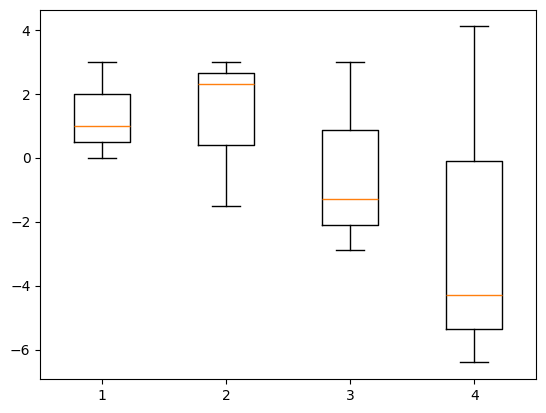

In [ ]:
import matplotlib.pyplot as plt

plt.boxplot(input_data)
plt.show()

In [ ]:
# 민맥스 스케일러를 이용한 스케일링
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
data_scaled = scaler.fit_transform(input_data)
data_scaled

array([[1.        , 0.        , 1.        , 0.        ],
       [0.        , 1.        , 0.27118644, 1.        ],
       [0.33333333, 0.84444444, 0.        , 0.2       ]])

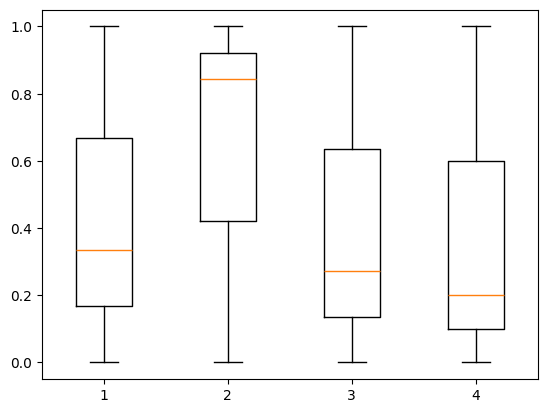

In [ ]:
plt.boxplot(data_scaled)
plt.show()

In [ ]:
# 스텐다드 스케일러를 이용한 스케일링
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
data_scaled = scaler.fit_transform(input_data)
data_scaled

array([[ 1.33630621, -1.39936232,  1.36473933, -0.9258201 ],
       [-1.06904497,  0.87670892, -0.36125453,  1.38873015],
       [-0.26726124,  0.5226534 , -1.0034848 , -0.46291005]])

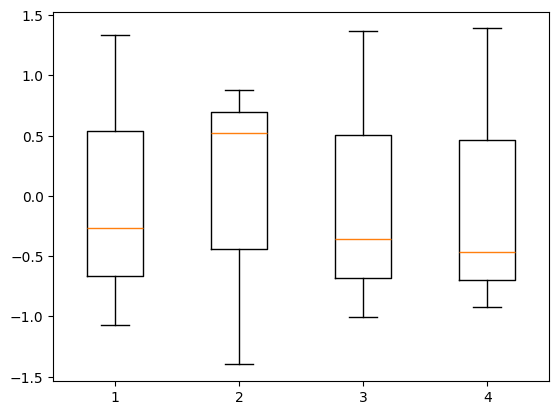

In [ ]:
plt.boxplot(data_scaled)
plt.show()

# 세일 데이터 전처리 실습

In [ ]:
# 훈련, 테스트용 데이터를 임포트한 후에 기본 데이터탐색을 수행
# -read_csv() 파일읽기
pd.read_csv('')
# -shape, dtypes, describe() 데이터검색
# -df.isnull().sum() 널값검색